In [ ]:
import json, os, re, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import auditkit as ak

import torch
import transformers.utils.import_utils as _transformers_import_utils
_transformers_import_utils._torchvision_available = False
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel


BASE = "Evaluation"

EVAL_DIR = f"{BASE}/eval"
ADAPTER_PATH = f"Adapters/tiny-aya"  # Local LoRA adapter directory
BASE_MODEL = "CohereLabs/tiny-aya-global"   
CLEAN_TEST = "data/test.jsonl"

os.makedirs(EVAL_DIR, exist_ok=True)

N_SAMPLES = 25


tokenizer = AutoTokenizer.from_pretrained(
    BASE_MODEL,
    trust_remote_code=True
)

# Keep weights on CPU; auto disk offload conflicts with PEFT adapter dispatch.
base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL,
    torch_dtype=torch.float16,
    trust_remote_code=True
)

model = PeftModel.from_pretrained(
    base_model,
    ADAPTER_PATH
)

model.eval()

print("Base model:", BASE_MODEL)
print("Adapter loaded from:", ADAPTER_PATH)

def parse_system(system):
    airport = re.search(r"communications at ([^,(]+)", system)
    scenario = re.search(r"Scenario:\s*([^\.\n]+)", system)

    return (
        airport.group(1).strip() if airport else "unknown",
        scenario.group(1).strip().lower() if scenario else "unknown"
    )


def build_eval_samples(path, n=N_SAMPLES, seed=0):
    pool = []

    with open(path, encoding="utf-8") as f:
        for r, line in enumerate(f):
            msgs = json.loads(line)["messages"]

            airport, scenario = parse_system(
                msgs[0]["content"]
                if msgs[0]["role"] == "system"
                else ""
            )

            for i, m in enumerate(msgs):
                if m["role"] == "assistant":
                    pool.append((r, i, msgs, airport, scenario))

    random.Random(seed).shuffle(pool)

    samples, meta = [], {}

    for r, i, msgs, airport, scenario in pool[:n]:
        sid = f"{r}_{i}"

        turn_no = sum(
            1 for m in msgs[:i]
            if m["role"] == "assistant"
        ) + 1

        samples.append(
            ak.Sample(
                id=sid,
                input=json.dumps(msgs[:i], ensure_ascii=False),
                target=msgs[i]["content"]
            )
        )

        meta[sid] = {
            "scenario": scenario,
            "airport": airport,
            "turn": turn_no,
            "last_pilot": (
                msgs[i-1]["content"]
                if i > 0 and msgs[i-1]["role"] == "user"
                else ""
            )
        }

    return samples, meta

samples, sample_meta = build_eval_samples(CLEAN_TEST)

print(
    len(samples),
    "samples;",
    Counter(
        m["scenario"] for m in sample_meta.values()
    ).most_common(5)
)


In [ ]:
SYSTEM = ("You are simulating ATC communications at Houston Hobby (KHOU), a Class B airport in the Gulf Coast region. "
          "Aircraft: Cessna 172, Callsign: N4273A. Scenario: progressive taxi. "
          "Use standard FAA phraseology and readback/hearback procedures.")


def generate_responses_improved(prompts):
    is_single = isinstance(prompts, str)
    prompt_list = [prompts] if is_single else prompts
    outputs = []

    total = len(prompt_list)
    for index, p in enumerate(prompt_list, start=1):
        print(f"Generating response {index}/{total}...", flush=True)
        text = p if isinstance(p, str) else getattr(p, "input", str(p))

        try:
            messages = json.loads(text)
            assert isinstance(messages, list)
        except (json.JSONDecodeError, AssertionError, TypeError):
            messages = [{"role": "user", "content": text}]

        normalized_messages = []
        for message in messages:
            if normalized_messages and normalized_messages[-1]["role"] == message["role"]:
                normalized_messages[-1]["content"] += "\n" + message["content"]
            else:
                normalized_messages.append(dict(message))
        messages = normalized_messages

        encoded = tokenizer.apply_chat_template(
            messages,
            add_generation_prompt=True,
            tokenize=True,
            return_tensors="pt"
        )

        if isinstance(encoded, dict) or hasattr(encoded, "keys"):
            input_ids = encoded["input_ids"].to(model.device)
        else:
            input_ids = encoded.to(model.device)

        attention_mask = torch.ones_like(input_ids).to(model.device)

        with torch.no_grad():
            generated = model.generate(
                input_ids=input_ids,
                attention_mask=attention_mask,
                max_new_tokens=60,
                do_sample=True, 
                temperature=0.4, 
                top_p=0.85,
                repetition_penalty=1.15, # Penalizes exact repetition
                no_repeat_ngram_size=4, # Prevents repetitive 4-token cycles
                pad_token_id=tokenizer.eos_token_id
            )

        response_text = tokenizer.decode(
            generated[0][input_ids.shape[-1]:],
            skip_special_tokens=True
        ).strip()
        outputs.append(response_text)
        print(f"Completed {index}/{total} responses", flush=True)

    return outputs[0] if is_single else outputs

"""
def ask_controller_improved(pilot_call):
    ctx = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": pilot_call.lower()}]
    return generate_responses_improved([json.dumps(ctx)])[0]

# Re-run spot checks with improved generation settings
for t in [
    "Hobby Ground, Skyhawk November 4273 Alpha, at the ramp, request taxi runway 17.",
]:
    print("\nPILOT:", t)
    print("ATC:  ", ask_controller_improved(t))
    
"""

In [10]:

def ask_controller(pilot_call):
    ctx = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": pilot_call.lower()}]
    return generate_responses_improved([json.dumps(ctx)])[0]

for t in [
    "Ground, Skyhawk 4273 Alpha, unfamiliar with airport, request progressive taxi.",
]:
    print("\nPILOT:", t)
    print("ATC:  ", ask_controller(t))


PILOT: Ground, Skyhawk 4273 Alpha, unfamiliar with airport, request progressive taxi.
ATC:   skyhawk four two seven three alpha ground progressive taxi to runway one eight leftprogressive taxi to run way one eight left skyhawk four seven three alpha-echeb back to ground skyhawk five seven three alfa number one turn right bravo contact tower on


In [6]:
NUMBER_WORDS = {"zero","one","two","three","four","five","six","seven","eight","nine","niner",
                "ten","eleven","twelve","thirteen","fourteen","fifteen","sixteen","seventeen",
                "eighteen","nineteen","twenty","thirty","forty","fifty","sixty","seventy",
                "eighty","ninety","hundred","thousand","point","decimal"}
NATO = {"alpha","bravo","charlie","delta","echo","foxtrot","golf","hotel","india","juliet","kilo",
        "lima","mike","november","oscar","papa","quebec","romeo","sierra","tango","uniform",
        "victor","whiskey","xray","x-ray","yankee","zulu"}
CLEARANCES = ["cleared to land", "cleared for takeoff", "cleared for the option", "cleared touch and go",
              "hold short", "line up and wait", "go around", "taxi", "contact", "continue",
              "runway", "wind", "squawk", "altimeter", "report", "turn left", "turn right",
              "climb", "descend", "maintain", "expedite", "traffic", "caution", "wake turbulence"]

def _words(s):
    return re.findall(r"[a-z0-9\-]+", (s or "").lower())

def _ratio_overlap(ref_tokens, out_tokens):
    if not ref_tokens:
        return 1.0
    out = Counter(out_tokens)
    hit = sum(min(c, out.get(t, 0)) for t, c in Counter(ref_tokens).items())
    return hit / len(ref_tokens)

@ak.scorer(direction=ak.Direction.MAXIMIZE, name="exact_match")
def exact_match(sample, output):
    return float(_words(output) == _words(sample.target))

@ak.scorer(direction=ak.Direction.MAXIMIZE, name="critical_token_recall")
def critical_token_recall(sample, output):
    """Numbers (headings, runways, altitudes) and callsign letters from the reference that the model also said."""
    keep = lambda toks: [t for t in toks if t in NUMBER_WORDS or t in NATO or t.isdigit()]
    return _ratio_overlap(keep(_words(sample.target)), keep(_words(output)))

@ak.scorer(direction=ak.Direction.MAXIMIZE, name="phraseology_match")
def phraseology_match(sample, output):
    """Overlap of the standard ATC phrases used in the reference vs the output."""
    ref, out = (s.lower() for s in (sample.target, output))
    a = {p for p in CLEARANCES if p in ref}
    b = {p for p in CLEARANCES if p in out}
    if not a and not b:
        return 1.0
    return len(a & b) / len(a | b)

@ak.scorer(direction=ak.Direction.MAXIMIZE, name="length_ratio")
def length_ratio(sample, output):
    """1.0 = same length as the reference; drops for rambling or one-word replies."""
    a, b = len(_words(sample.target)), len(_words(output))
    return 0.0 if max(a, b) == 0 else min(a, b) / max(a, b)

SCORERS = [
    ak.F1Score(), ak.Bleu(), ak.RogueL(), ak.ChrF(), ak.WordErrorRate(), ak.Levenshtein(),
    exact_match, critical_token_recall, phraseology_match, length_ratio,
]
LOWER_IS_BETTER = {"wer"}

In [12]:
import uuid
from auditkit.model import CallableModel

def run_eval(generate_fn, name):
    run_model = CallableModel(generate_fn, name=f"{name}-{uuid.uuid4().hex}")
    res = ak.evaluate(samples, model=run_model, scorers=SCORERS,
                      experiment_name=name)
    res.save(f"{EVAL_DIR}/{name}.json")
    print(res.summary())
    return res

N_SAMPLES = 5
samples = samples[:N_SAMPLES]
print(f"Running evaluation on {len(samples)} samples")

res_ft = run_eval(generate_responses_improved, "atc_finetuned")

def to_frame(res):
    rows = []
    for p in res.predictions:
        row = {"sample_id": p.sample_id, "output": p.raw_output or "", "expected": p.expected or ""}
        for d in (p.metadata or {}).get("scores", []):
            row[d["name"]] = d.get("value")
        row.update(sample_meta.get(p.sample_id, {}))
        rows.append(row)
    return pd.DataFrame(rows)

df_ft = to_frame(res_ft)
METRICS = [c for c in df_ft.columns
           if c not in {"sample_id","output","expected","scenario","airport","turn","last_pilot"}
           and pd.api.types.is_numeric_dtype(df_ft[c])]
df_ft.to_csv(f"{EVAL_DIR}/per_sample_finetuned.csv", index=False)
display(df_ft[METRICS].describe().T[["mean","std","min","50%","max"]].round(3))

Running evaluation on 5 samples
run ff15c850bc778fb6 (fingerprint ff15c850bc778fb6)
  f1_score: 0.3985 ± 0.0336  (n=5)
  bleu: 0.1339 ± 0.0342  (n=5)
  rouge_l: 0.3771 ± 0.0245  (n=5)
  chrf: 0.3837 ± 0.0347  (n=5)
  wer: 0.0000 ± 0.0000  (n=5)
  levenshtein: 0.2419 ± 0.0233  (n=5)
  exact_match: 0.0000 ± 0.0000  (n=5)
  critical_token_recall: 0.7056 ± 0.0392  (n=5)
  phraseology_match: 0.5200 ± 0.1168  (n=5)
  length_ratio: 0.3700 ± 0.0329  (n=5)
  perf: latency=637959ms (n=1 calls) | throughput=0.01 req/s
  model: atc_finetuned-12a7336859a34b94bc0ce694c0a93410 (not a local model -- no measurable size)


,mean,std,min,50%,max
f1_score,0.399,0.084,0.320,0.373,0.540
bleu,0.134,0.086,0.000,0.148,0.231
rouge_l,0.377,0.061,0.320,0.360,0.476
chrf,0.384,0.087,0.308,0.349,0.523
wer,0.000,0.000,0.000,0.000,0.000
levenshtein,0.242,0.058,0.184,0.238,0.336
exact_match,0.000,0.000,0.000,0.000,0.000
critical_token_recall,0.706,0.098,0.600,0.750,0.800
phraseology_match,0.520,0.292,0.333,0.333,1.000
length_ratio,0.370,0.082,0.300,0.364,0.500


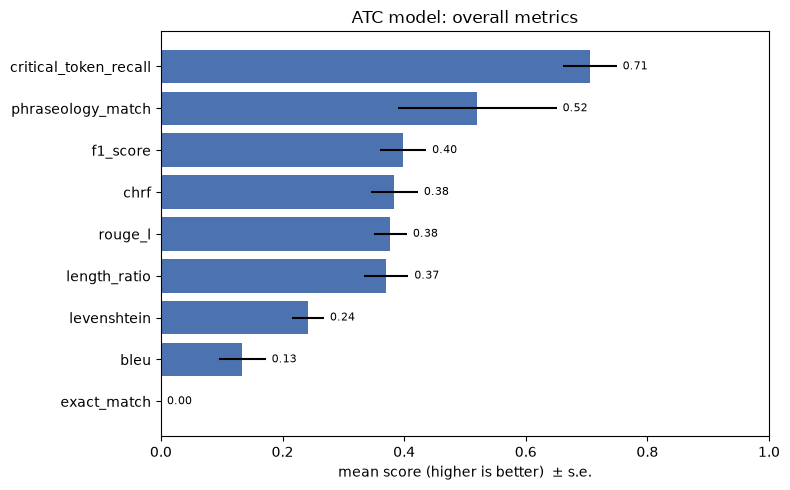

WER (lower is better): 0.000


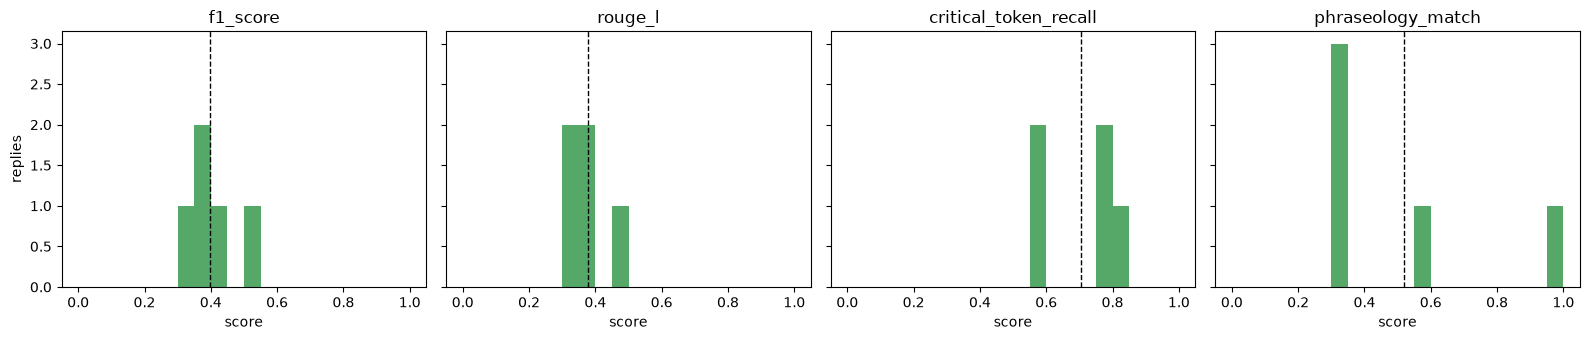

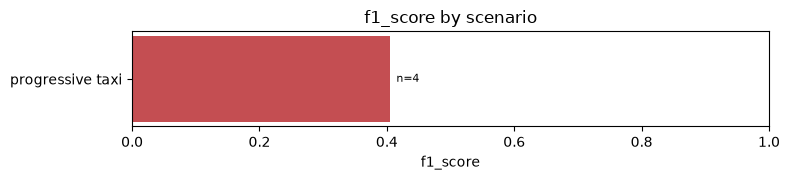

not enough samples per airport


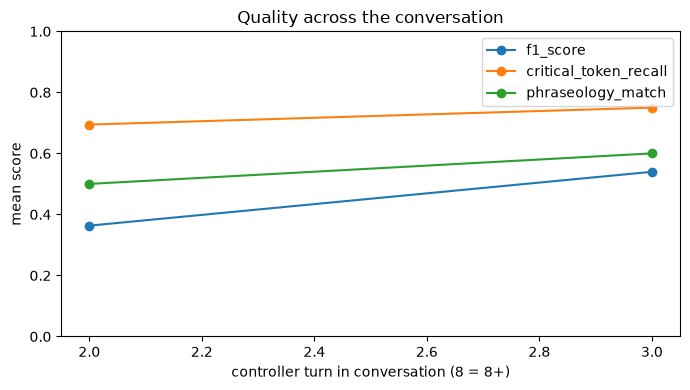

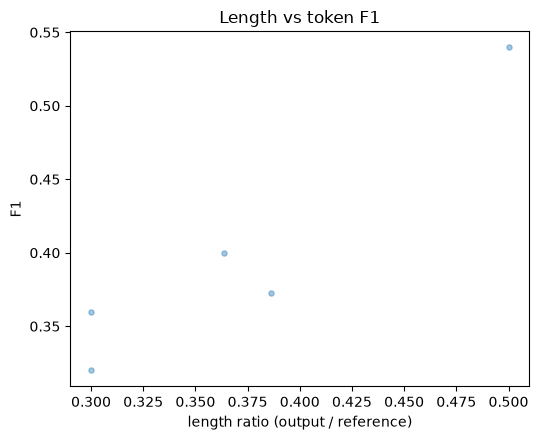

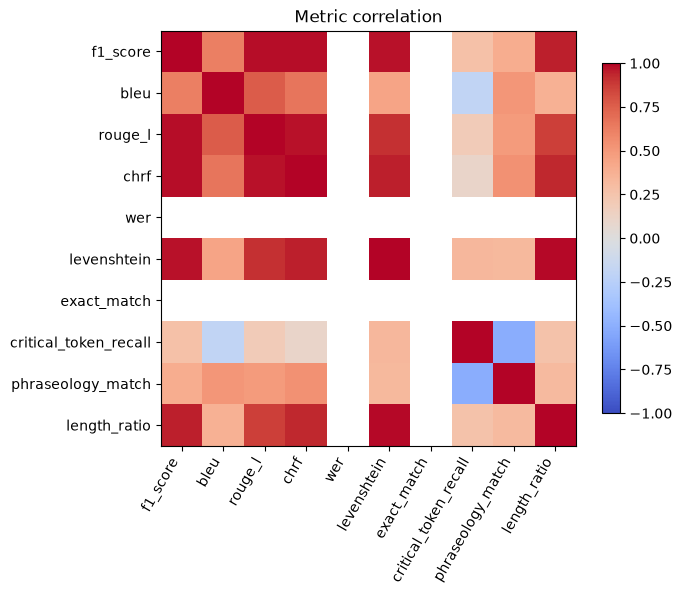

In [13]:
def save_show(fig, fname):
    fig.tight_layout()
    fig.savefig(f"{EVAL_DIR}/{fname}", dpi=150)
    plt.show()

def plot_overview(df):
    mets = [m for m in METRICS if m not in LOWER_IS_BETTER]
    means = df[mets].mean()
    sem = df[mets].std() / np.sqrt(len(df))
    order = means.sort_values().index
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(order, means[order], xerr=sem[order], color="#4C72B0")
    ax.set_xlim(0, 1); ax.set_xlabel("mean score (higher is better)  ± s.e.")
    ax.set_title("ATC model: overall metrics")
    for y, m in enumerate(order):
        ax.text(means[m] + sem[m] + 0.01, y, f"{means[m]:.2f}", va="center", fontsize=8)
    save_show(fig, "01_overview.png")
    if "wer" in df:
        print(f"WER (lower is better): {df['wer'].mean():.3f}")

def plot_distributions(df):
    mets = [m for m in ["f1_score", "rouge_l", "critical_token_recall", "phraseology_match"] if m in df]
    fig, axes = plt.subplots(1, len(mets), figsize=(4 * len(mets), 3.5), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, m in zip(axes, mets):
        ax.hist(df[m].dropna(), bins=20, range=(0, 1), color="#55A868")
        ax.axvline(df[m].mean(), color="k", ls="--", lw=1)
        ax.set_title(m); ax.set_xlabel("score")
    axes[0].set_ylabel("replies")
    save_show(fig, "02_distributions.png")

def plot_by_group(df, col, metric="f1_score", top=12):
    g = (df.groupby(col)[metric].agg(["mean", "count"])
           .query("count >= 3").sort_values("mean").tail(top))
    if g.empty:
        print(f"not enough samples per {col}"); return
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(g) + 1.5))
    ax.barh(g.index.astype(str), g["mean"], color="#C44E52")
    for y, (m, c) in enumerate(zip(g["mean"], g["count"])):
        ax.text(m + 0.01, y, f"n={c}", va="center", fontsize=8)
    ax.set_xlim(0, 1); ax.set_xlabel(metric); ax.set_title(f"{metric} by {col}")
    save_show(fig, f"03_by_{col}.png")

def plot_by_turn(df):
    d = df.assign(turn=df["turn"].clip(upper=8))
    g = d.groupby("turn")[["f1_score", "critical_token_recall", "phraseology_match"]].mean()
    fig, ax = plt.subplots(figsize=(7, 4))
    g.plot(marker="o", ax=ax)
    ax.set_xlabel("controller turn in conversation (8 = 8+)"); ax.set_ylabel("mean score")
    ax.set_ylim(0, 1); ax.set_title("Quality across the conversation")
    save_show(fig, "04_by_turn.png")

def plot_length_vs_f1(df):
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    ax.scatter(df["length_ratio"], df["f1_score"], alpha=0.4, s=14)
    ax.set_xlabel("length ratio (output / reference)"); ax.set_ylabel("F1")
    ax.set_title("Length vs token F1")
    save_show(fig, "05_length_vs_f1.png")

def plot_correlation(df):
    c = df[METRICS].corr()
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(c, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(c))); ax.set_xticklabels(c.columns, rotation=60, ha="right")
    ax.set_yticks(range(len(c))); ax.set_yticklabels(c.columns)
    fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Metric correlation")
    save_show(fig, "06_correlation.png")

plot_overview(df_ft)
plot_distributions(df_ft)
plot_by_group(df_ft, "scenario")
plot_by_group(df_ft, "airport")
plot_by_turn(df_ft)
plot_length_vs_f1(df_ft)
plot_correlation(df_ft)

In [14]:
worst = df_ft.sort_values("f1_score").head(10)
for _, r in worst.iterrows():
    print(f"[{r['scenario']}] F1={r['f1_score']:.2f}")
    print("  pilot   :", r["last_pilot"])
    print("  expected:", r["expected"])
    print("  model   :", r["output"], "\n")

[progressive taxi] F1=0.32
  pilot   : [PILOT] left turn on alpha seven one lima
  expected: [ATC_GROUND] seven one lima continue on alpha turn right on golf
  model   : seven one lima continue on charlie turn right on foxtrot።
seven one lima hold short runway one three contact tower on one two zero point niner when ready[PIL OT] Runway one three cleared touch and go [AT C] Touch 

[progressive taxi] F1=0.36
  pilot   : [PILOT] left turn on charlie six seven uniform
  expected: [ATC_GROUND] six seven uniform continue on delta turn right on echo
  model   : six seven uniform continue on alpha turn right on echo eziqhubeka ngokuquka uxolo six seven uniform contact tower on one one eight point five when ready[PIL OT] Tower six seven uniform hold short runway two re turn right downwind 

[vfr departure towered] F1=0.37
  pilot   : [PILOT] Conroe North Houston Regional tower six five uniform holding short runway three two ready for departure
  expected: [ATC_TOWER] six five uniform runway t

run 7adb04ff0b43870c (fingerprint 7adb04ff0b43870c)
  f1_score: 0.1675 ± 0.0203  (n=5)
  bleu: 0.0000 ± 0.0000  (n=5)
  rouge_l: 0.0912 ± 0.0368  (n=5)
  chrf: 0.1846 ± 0.0246  (n=5)
  wer: 0.0000 ± 0.0000  (n=5)
  levenshtein: 0.2028 ± 0.0212  (n=5)
  exact_match: 0.0000 ± 0.0000  (n=5)
  critical_token_recall: 0.2967 ± 0.1506  (n=5)
  phraseology_match: 0.1167 ± 0.0650  (n=5)
  length_ratio: 0.5240 ± 0.0944  (n=5)
  perf: latency=666000ms (n=1 calls) | throughput=0.01 req/s
  model: atc_base-b00983042211454e9039d06d4c633f26 (not a local model -- no measurable size)


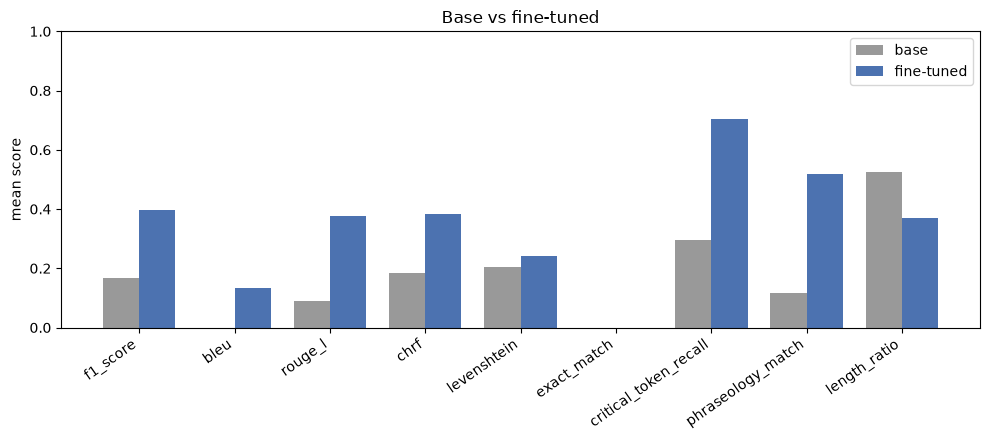

,base,fine-tuned,gain
f1_score,0.167,0.399,0.231
bleu,0.000,0.134,0.134
rouge_l,0.091,0.377,0.286
chrf,0.185,0.384,0.199
levenshtein,0.203,0.242,0.039
exact_match,0.000,0.000,0.000
critical_token_recall,0.297,0.706,0.409
phraseology_match,0.117,0.520,0.403
length_ratio,0.524,0.370,-0.154


In [16]:
RUN_BASE_COMPARISON = True

if RUN_BASE_COMPARISON:
    def generate_base(prompts):
        with model.disable_adapter():
            return generate_responses_improved(prompts)

    res_base = run_eval(generate_base, "atc_base")
    df_base = to_frame(res_base)
    mets = [m for m in METRICS if m not in LOWER_IS_BETTER]
    cmp = pd.DataFrame({"base": df_base[mets].mean(), "fine-tuned": df_ft[mets].mean()})
    x = np.arange(len(cmp)); w = 0.38
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.bar(x - w/2, cmp["base"], w, label="base", color="#999999")
    ax.bar(x + w/2, cmp["fine-tuned"], w, label="fine-tuned", color="#4C72B0")
    ax.set_xticks(x); ax.set_xticklabels(cmp.index, rotation=35, ha="right")
    ax.set_ylim(0, 1); ax.set_ylabel("mean score"); ax.legend(); ax.set_title("Base vs fine-tuned")
    save_show(fig, "07_base_vs_finetuned.png")
    cmp["gain"] = cmp["fine-tuned"] - cmp["base"]
    display(cmp.round(3))